In [4]:
import numpy as np 
import pandas as pd
from tqdm import tqdm 
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
import matplotlib.pyplot as plt
import statsmodels.api as sn
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA


In [5]:
df=pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\FMAC-HPI_24420.csv")
df.head()

,Date,NSA Value,SA Value
0,31-01-1975,24.739893,24.687815
1,28-02-1975,25.266825,25.200482
2,31-03-1975,25.765667,25.633002
3,30-04-1975,26.212724,26.009987
4,31-05-1975,26.628081,26.350592


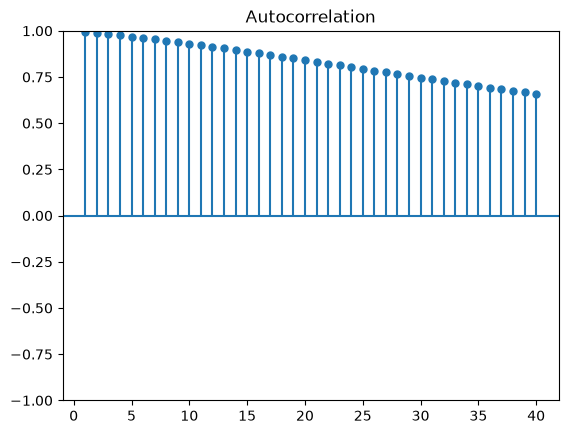

In [6]:
plot_acf(df['NSA Value'],lags=40,alpha=None,zero=False)
plt.show()

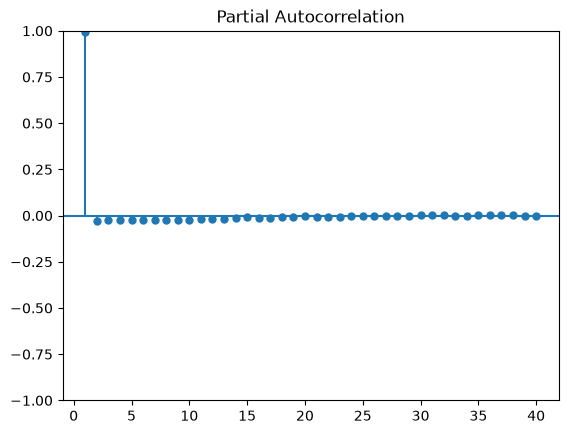

In [7]:
plot_pacf(df['NSA Value'],lags=40,alpha=None,zero=False)

plt.show()

In [9]:
y=df['NSA Value']
y_train=y[:-12]
y_test=y[-12:]

In [10]:
model=ARIMA(y_train,order=(2,1,1))
model_fit=model.fit()
print('Coefficient: %s' % model_fit.params)
predictions=model_fit.predict(start=len(y_train),end=len(y_train)+len(y_test)-1)
error=root_mean_squared_error(y_test,predictions)
error

Coefficient: ar.L1     1.472866
ar.L2    -0.589460
ma.L1     0.999570
sigma2    0.035253
dtype: float64


3.1911612126550555

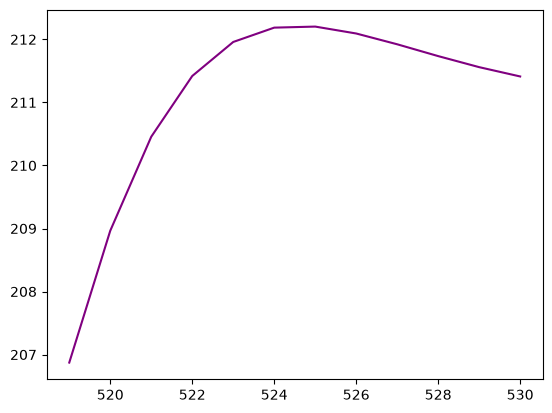

In [12]:
predictions.plot(color='purple')
plt.show()

# Auto-ARIMA

In [15]:
from pmdarima.arima import auto_arima

In [16]:
model=auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-258.744, Time=1.04 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1625.721, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=545.901, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.43 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1668.139, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-211.845, Time=0.68 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.76 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.23 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.04 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.79 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.76 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.50 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.39 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=-254.857, Time=0.67 sec

Best model:  ARIMA(2,1,2)(0,0,0)[0] intercept
Total fit time: 12.496 seco

In [17]:
model.bse

<bound method ARIMA.bse of ARIMA(order=(2, 1, 2), scoring_args={}, suppress_warnings=True)>

In [19]:
forecast=model.predict(n_periods=len(y_test))
forecast=pd.DataFrame(forecast,index=y_test.index,columns=['Prediction'])
rms=root_mean_squared_error(y_test,forecast)
print('TEST RMSE %:',rms)

TEST RMSE %: 4.213475458383349


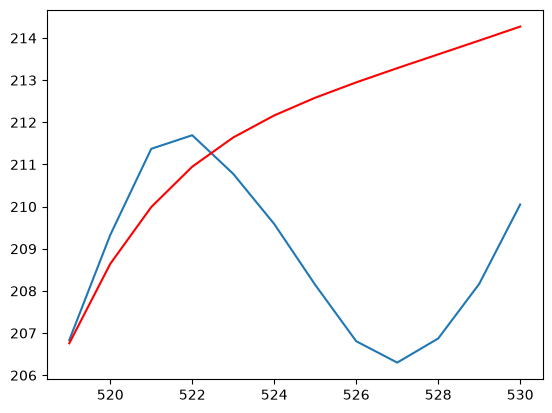

In [26]:
plt.plot(y_test)
plt.plot(forecast,color='r')
plt.show()